## Ensemble

### โจทย์
- เลือก algorithm สำหรับใช้ Classification 1 ตัว โดยสามารมใช้ library ได้
- เขียน Parallel Computing ที่ builin python และ numpy ในการทำ Bagging ด้วยตัวเอง
- เขียน bosting แบบปกติได้เลย

### Import Library

In [19]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

### Import Data

In [20]:
# โหลดชุดข้อมูล Iris จากไฟล์ CSV
iris_df = pd.read_csv("data_set/Iris.csv")

# แยก Features (ตัดคอลัมน์ Id และ Species ออก เพื่อป้องกันโมเดลจำลำดับ Id)
X = iris_df[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]].to_numpy()

# แปลงชื่อสายพันธุ์ดอกไม้ (Target) จากข้อความให้เป็นตัวเลข 0, 1, 2
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(iris_df["Species"])

# ตรวจสอบขนาดข้อมูลและจำนวนตัวอย่างในแต่ละคลาส
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Classes:", list(label_encoder.classes_))
print("Class counts:", np.bincount(y))
iris_df.head()

Shape of X: (150, 4)
Shape of y: (150,)
Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Class counts: [50 50 50]


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### Function Visualization

In [21]:
# วาดตาราง Confusion Matrix พร้อมตัวเลขจำนวนตัวอย่างในแต่ละช่อง
def plot_confusion_matrix_ax(ax, y_true, y_pred, class_names, title, cmap_name="Blues"):
    """ฟังก์ชันวาด Confusion Matrix ลงบน Axes ที่กำหนด"""
    cm = confusion_matrix(y_true, y_pred)
    ax.imshow(cm, interpolation="nearest", cmap=cmap_name)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

    tick_marks = np.arange(len(class_names))
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(class_names, rotation=20, ha="right")
    ax.set_yticklabels(class_names)

    # แสดงตัวเลขจำนวนตัวอย่างในแต่ละช่องของ Confusion Matrix
    threshold = cm.max() / 2.0
    for row_index in range(cm.shape[0]):
        for col_index in range(cm.shape[1]):
            text_color = "white" if cm[row_index, col_index] > threshold else "black"
            ax.text(
                col_index,
                row_index,
                str(cm[row_index, col_index]),
                ha="center",
                va="center",
                color=text_color,
                fontsize=12,
                fontweight="bold"
            )

In [22]:
# สร้างตารางพิกัด 2 มิติ และให้โมเดลทำนายขอบเขตการแบ่งคลาส (Decision Boundary)
def create_2d_decision_grid(X_scaled, model, feature_x_index=2, feature_y_index=3, grid_step=0.05):
    """ฟังก์ชันสร้างตารางพิกัด 2 มิติ และทำนายขอบเขตการแบ่งคลาสจากโมเดล 4 มิติ"""
    x_min = X_scaled[:, feature_x_index].min() - 0.6
    x_max = X_scaled[:, feature_x_index].max() + 0.6
    y_min = X_scaled[:, feature_y_index].min() - 0.6
    y_max = X_scaled[:, feature_y_index].max() + 0.6

    grid_x, grid_y = np.meshgrid(
        np.arange(x_min, x_max, grid_step),
        np.arange(y_min, y_max, grid_step)
    )

    # สร้างข้อมูลจำลอง 4 มิติ โดยกำหนดอีก 2 Features ที่เหลือเป็น 0 (ค่าเฉลี่ยหลัง Scaling)
    grid_points = np.zeros((grid_x.size, X_scaled.shape[1]))
    grid_points[:, feature_x_index] = grid_x.ravel()
    grid_points[:, feature_y_index] = grid_y.ravel()

    grid_predictions = model.predict(grid_points).reshape(grid_x.shape)
    return grid_x, grid_y, grid_predictions

In [23]:
# แสดงผลขั้นตอนการเทรน (Decision Boundary + Support Vectors) และผลลัพธ์ชุด Train
def plot_training_visualization(X_train_scaled, y_train, y_pred_train, model, class_names):
    """ฟังก์ชันแสดงผลขั้นตอนการเทรน (Support Vectors + ขอบเขต) และผลลัพธ์สุดท้ายของชุด Train"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # กราฟซ้าย: แสดงจุดข้อมูล Train, ขอบเขตการแบ่งคลาส และ Support Vectors
    grid_x, grid_y, grid_predictions = create_2d_decision_grid(
        X_scaled=X_train_scaled,
        model=model,
        feature_x_index=2,
        feature_y_index=3,
        grid_step=0.05
    )
    axes[0].contourf(grid_x, grid_y, grid_predictions, alpha=0.25, cmap="viridis")

    for class_index, class_label in enumerate(class_names):
        class_mask = (y_train == class_index)
        axes[0].scatter(
            X_train_scaled[class_mask, 2],
            X_train_scaled[class_mask, 3],
            label=class_label,
            edgecolors="black",
            s=50
        )

    # ไฮไลต์จุดที่เป็น Support Vectors (เฉพาะโมเดลที่มี support_vectors_ เช่น SVC)
    if hasattr(model, "support_vectors_"):
        axes[0].scatter(
            model.support_vectors_[:, 2],
            model.support_vectors_[:, 3],
            s=140,
            facecolors="none",
            edgecolors="red",
            linewidths=1.5,
            label=f"Support Vectors ({len(model.support_vectors_)})"
        )
    axes[0].set_title("Training Phase: Decision Boundary & Support Vectors", fontsize=12)
    axes[0].set_xlabel("PetalLengthCm (Scaled)")
    axes[0].set_ylabel("PetalWidthCm (Scaled)")
    axes[0].legend(loc="upper left", fontsize=9)

    # กราฟขวา: แสดง Confusion Matrix ของผลลัพธ์สุดท้ายในชุด Train
    train_accuracy = accuracy_score(y_train, y_pred_train)
    plot_confusion_matrix_ax(
        ax=axes[1],
        y_true=y_train,
        y_pred=y_pred_train,
        class_names=class_names,
        title=f"Training Result Confusion Matrix (Acc: {train_accuracy:.4f})",
        cmap_name="Blues"
    )

    plt.tight_layout()
    plt.show()

In [24]:
# แสดงผลลัพธ์การเทส (จุดที่ทายถูก/ทายผิดบนขอบเขต) และ Confusion Matrix ของชุด Test
def plot_testing_visualization(X_test_scaled, y_test, y_pred_test, model, class_names):
    """ฟังก์ชันแสดงผลลัพธ์การเทส (จุดที่ทายถูก/ทายผิดบนขอบเขต) และ Confusion Matrix ของชุด Test"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # กราฟซ้าย: แสดงจุดข้อมูล Test บนขอบเขตการตัดสินใจ พร้อมวงกลมสีแดงจุดที่ทายผิด
    grid_x, grid_y, grid_predictions = create_2d_decision_grid(
        X_scaled=X_test_scaled,
        model=model,
        feature_x_index=2,
        feature_y_index=3,
        grid_step=0.05
    )
    axes[0].contourf(grid_x, grid_y, grid_predictions, alpha=0.25, cmap="viridis")

    for class_index, class_label in enumerate(class_names):
        class_mask = (y_test == class_index)
        axes[0].scatter(
            X_test_scaled[class_mask, 2],
            X_test_scaled[class_mask, 3],
            label=class_label,
            edgecolors="black",
            s=60
        )

    # ตรวจสอบและไฮไลต์จุดที่โมเดลทายผิดในชุด Test
    misclassified_mask = (y_test != y_pred_test)
    if np.any(misclassified_mask):
        axes[0].scatter(
            X_test_scaled[misclassified_mask, 2],
            X_test_scaled[misclassified_mask, 3],
            s=180,
            facecolors="none",
            edgecolors="red",
            linewidths=2.0,
            label=f"Misclassified ({np.sum(misclassified_mask)})"
        )

    axes[0].set_title("Testing Phase: Predictions on Decision Boundary", fontsize=12)
    axes[0].set_xlabel("PetalLengthCm (Scaled)")
    axes[0].set_ylabel("PetalWidthCm (Scaled)")
    axes[0].legend(loc="upper left", fontsize=9)

    # กราฟขวา: แสดง Confusion Matrix ของผลลัพธ์การเทส
    test_accuracy = accuracy_score(y_test, y_pred_test)
    plot_confusion_matrix_ax(
        ax=axes[1],
        y_true=y_test,
        y_pred=y_pred_test,
        class_names=class_names,
        title=f"Testing Result Confusion Matrix (Acc: {test_accuracy:.4f})",
        cmap_name="Greens"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# แสดงผลความคืบหน้าของ Boosting: ซ้าย = โมเดลเดี่ยวรอบนั้น, กลาง = กราฟแท่ง, ขวา = ผลโหวต Ensemble จริง
def plot_boosting_round_progress(X_train_scaled, y_train, y_pred_round, single_model, y_pred_ensemble, ensemble_model, round_number, class_names):
    """ฟังก์ชันแสดงผลความคืบหน้าในแต่ละรอบของ Boosting: โมเดลเดี่ยว vs กราฟแท่งรายสายพันธุ์ vs ผลรวมโหวต Ensemble"""
    total_samples = len(y_train)
    correct_count = int(np.sum(y_pred_round == y_train))
    wrong_count = total_samples - correct_count
    correct_percent = (correct_count / total_samples) * 100.0
    wrong_percent = (wrong_count / total_samples) * 100.0

    ens_correct_count = int(np.sum(y_pred_ensemble == y_train))
    ens_wrong_count = total_samples - ens_correct_count
    ens_correct_percent = (ens_correct_count / total_samples) * 100.0
    ens_wrong_percent = (ens_wrong_count / total_samples) * 100.0

    fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

    # กราฟซ้าย: แสดงผลของโมเดลเดี่ยวในรอบนั้น (Single Model Round X)
    grid_x, grid_y, grid_predictions_single = create_2d_decision_grid(
        X_scaled=X_train_scaled,
        model=single_model,
        feature_x_index=2,
        feature_y_index=3,
        grid_step=0.05
    )
    axes[0].contourf(grid_x, grid_y, grid_predictions_single, alpha=0.25, cmap="viridis")

    for class_index, class_label in enumerate(class_names):
        class_mask = (y_train == class_index)
        axes[0].scatter(
            X_train_scaled[class_mask, 2],
            X_train_scaled[class_mask, 3],
            label=class_label,
            edgecolors="black",
            s=45
        )

    wrong_mask = (y_pred_round != y_train)
    if np.any(wrong_mask):
        axes[0].scatter(
            X_train_scaled[wrong_mask, 2],
            X_train_scaled[wrong_mask, 3],
            s=150,
            facecolors="none",
            edgecolors="red",
            linewidths=2.0,
            label=f"Misclassified ({wrong_count})"
        )

    axes[0].set_title(
        f"Model {round_number} Only | Correct: {correct_percent:.2f}% ({correct_count}) | Wrong: {wrong_percent:.2f}% ({wrong_count})",
        fontsize=10
    )
    axes[0].set_xlabel("PetalLengthCm (Scaled)")
    axes[0].set_ylabel("PetalWidthCm (Scaled)")
    axes[0].legend(loc="upper left", fontsize=8)

    # กราฟกลาง: แสดงจำนวนและเปอร์เซ็นต์ที่แบ่งถูก/ผิดแยกตามสายพันธุ์ของโมเดลรอบนั้น
    correct_per_class = []
    wrong_per_class = []
    for class_index in range(len(class_names)):
        class_mask = (y_train == class_index)
        class_total = int(np.sum(class_mask))
        class_correct = int(np.sum((y_pred_round == y_train) & class_mask))
        class_wrong = class_total - class_correct
        correct_per_class.append((class_correct / class_total) * 100.0)
        wrong_per_class.append((class_wrong / class_total) * 100.0)

    x_positions = np.arange(len(class_names))
    bar_width = 0.35
    bars_correct = axes[1].bar(x_positions - bar_width / 2, correct_per_class, width=bar_width, color="seagreen", label="Correct (%)")
    bars_wrong = axes[1].bar(x_positions + bar_width / 2, wrong_per_class, width=bar_width, color="crimson", label="Wrong (%)")

    for bar in bars_correct:
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width() / 2, height + 1.5, f"{height:.1f}%", ha="center", va="bottom", fontsize=9)
    for bar in bars_wrong:
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width() / 2, height + 1.5, f"{height:.1f}%", ha="center", va="bottom", fontsize=9)

    axes[1].set_title(f"Model {round_number}: Correct vs Wrong (%) by Species", fontsize=10)
    axes[1].set_xticks(x_positions)
    axes[1].set_xticklabels(class_names)
    axes[1].set_ylim(0, 115)
    axes[1].set_ylabel("Percentage (%)")
    axes[1].legend(loc="upper right", fontsize=8)

    # กราฟขวา: แสดงผลลัพธ์ที่โมเดลรวม (Ensemble) ทายจริงจนถึงรอบนั้น
    grid_x_ens, grid_y_ens, grid_predictions_ens = create_2d_decision_grid(
        X_scaled=X_train_scaled,
        model=ensemble_model,
        feature_x_index=2,
        feature_y_index=3,
        grid_step=0.05
    )
    axes[2].contourf(grid_x_ens, grid_y_ens, grid_predictions_ens, alpha=0.25, cmap="viridis")

    for class_index, class_label in enumerate(class_names):
        class_mask = (y_train == class_index)
        axes[2].scatter(
            X_train_scaled[class_mask, 2],
            X_train_scaled[class_mask, 3],
            label=class_label,
            edgecolors="black",
            s=45
        )

    ens_wrong_mask = (y_pred_ensemble != y_train)
    if np.any(ens_wrong_mask):
        axes[2].scatter(
            X_train_scaled[ens_wrong_mask, 2],
            X_train_scaled[ens_wrong_mask, 3],
            s=150,
            facecolors="none",
            edgecolors="red",
            linewidths=2.0,
            label=f"Misclassified ({ens_wrong_count})"
        )

    axes[2].set_title(
        f"Ensemble (1-{round_number}) | Correct: {ens_correct_percent:.2f}% ({ens_correct_count}) | Wrong: {ens_wrong_percent:.2f}% ({ens_wrong_count})",
        fontsize=10
    )
    axes[2].set_xlabel("PetalLengthCm (Scaled)")
    axes[2].set_ylabel("PetalWidthCm (Scaled)")
    axes[2].legend(loc="upper left", fontsize=8)

    plt.tight_layout()
    plt.show()

In [ ]:
# แสดงผลลัพธ์สุดท้ายของ Boosting เปรียบเทียบทั้งชุด Train และชุด Test
def plot_boosting_final_summary(y_train, y_pred_train, y_test, y_pred_test, class_names):
    """ฟังก์ชันแสดงผลลัพธ์สุดท้ายของ Boosting ด้วยกราฟแท่งเปรียบเทียบ Train vs Test และสัดส่วนทายถูก/ผิดรายสายพันธุ์"""
    train_total = len(y_train)
    train_correct = int(np.sum(y_pred_train == y_train))
    train_accuracy = accuracy_score(y_train, y_pred_train)

    test_total = len(y_test)
    test_correct = int(np.sum(y_pred_test == y_test))
    test_accuracy = accuracy_score(y_test, y_pred_test)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # กราฟซ้าย: เปรียบเทียบ Train Accuracy (%) และ Test Accuracy (%) พร้อมจำนวนที่ทายถูก
    dataset_labels = ["Train Set", "Test Set"]
    accuracy_values = [train_accuracy * 100.0, test_accuracy * 100.0]
    correct_summaries = [f"{train_correct}/{train_total}", f"{test_correct}/{test_total}"]
    summary_bars = axes[0].bar(dataset_labels, accuracy_values, color=["steelblue", "seagreen"], width=0.45)

    for bar, count_text in zip(summary_bars, correct_summaries):
        height = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            height + 1.5,
            f"{height:.2f}%\n({count_text})",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

    axes[0].set_title("Final Boosting Accuracy: Train vs Test", fontsize=12)
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_ylim(0, 118)

    # กราฟขวา: กราฟแท่งแสดงสัดส่วนทายถูก vs ทายผิด (%) แยกตามสายพันธุ์ในชุด Test
    class_correct_percents = []
    class_wrong_percents = []
    for class_index in range(len(class_names)):
        class_mask = (y_test == class_index)
        class_total = int(np.sum(class_mask))
        if class_total > 0:
            class_correct_rate = float(np.mean(y_pred_test[class_mask] == y_test[class_mask]) * 100.0)
        else:
            class_correct_rate = 0.0
        class_correct_percents.append(class_correct_rate)
        class_wrong_percents.append(100.0 - class_correct_rate)

    x_positions = np.arange(len(class_names))
    bar_width = 0.35
    bars_correct = axes[1].bar(x_positions - bar_width / 2, class_correct_percents, width=bar_width, color="seagreen", label="Correct (%)")
    bars_wrong = axes[1].bar(x_positions + bar_width / 2, class_wrong_percents, width=bar_width, color="crimson", label="Wrong (%)")

    for bar in bars_correct:
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width() / 2, height + 1.5, f"{height:.1f}%", ha="center", va="bottom", fontsize=9)

    for bar in bars_wrong:
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width() / 2, height + 1.5, f"{height:.1f}%", ha="center", va="bottom", fontsize=9)

    axes[1].set_title(f"Test Set: Correct vs Wrong (%) by Species ({test_correct}/{test_total})", fontsize=12)
    axes[1].set_xticks(x_positions)
    axes[1].set_xticklabels(class_names)
    axes[1].set_ylabel("Percentage (%)")
    axes[1].set_ylim(0, 115)
    axes[1].legend(loc="upper right", fontsize=9)

    plt.tight_layout()
    plt.show()

### Support Vector Classification

#### ขั้นตอนการ trein

Training Time: 0.0020 seconds
Number of Support Vectors: 47
Train Accuracy: 0.9750


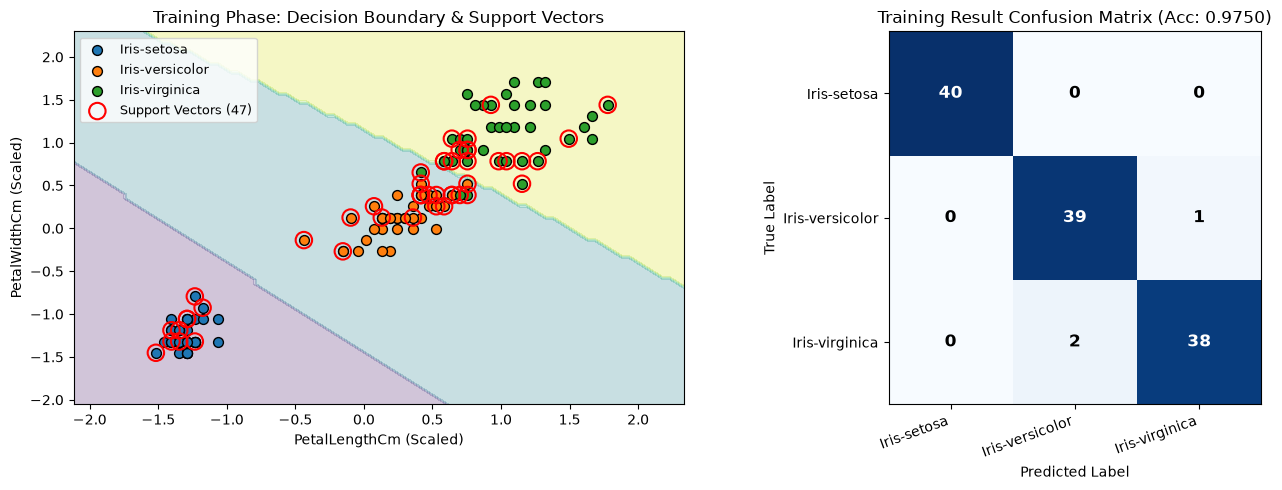

In [25]:
# แบ่งข้อมูลเป็นชุด Train (80%) และ Test (20%) โดยรักษาสัดส่วนของแต่ละคลาสให้เท่ากัน
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# ปรับสเกลข้อมูลให้มีค่าเฉลี่ย 0 และส่วนเบี่ยงเบนมาตรฐาน 1 (จำเป็นสำหรับ SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# สร้างโมเดล Support Vector Classifier (Single Model Baseline) พร้อมระบุพารามิเตอร์ชัดเจน
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

# ฝึกสอนโมเดลบนชุดข้อมูล Train และจับเวลาที่ใช้ในการเทรน
start_time = time.perf_counter()
svm_model.fit(X_train_scaled, y_train)
svm_train_time = time.perf_counter() - start_time

# ตรวจสอบผลลัพธ์สุดท้ายของการเทรนบนชุด Train
y_pred_train_svm = svm_model.predict(X_train_scaled)
svm_train_accuracy = accuracy_score(y_train, y_pred_train_svm)

print(f"Training Time: {svm_train_time:.4f} seconds")
print(f"Number of Support Vectors: {len(svm_model.support_vectors_)}")
print(f"Train Accuracy: {svm_train_accuracy:.4f}")

# แสดง Visualization ของขั้นตอนการเทรนและผลลัพธ์ชุด Train
plot_training_visualization(
    X_train_scaled=X_train_scaled,
    y_train=y_train,
    y_pred_train=y_pred_train_svm,
    model=svm_model,
    class_names=label_encoder.classes_
)

#### ขั้นตอนการ test

Test Accuracy: 0.9667

Test Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



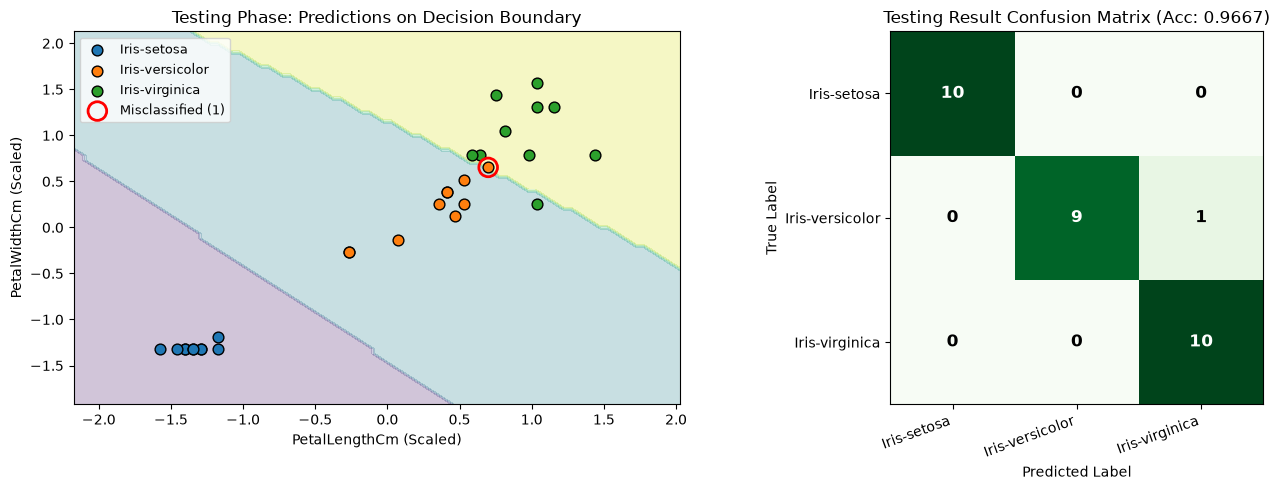

In [26]:
# นำโมเดลที่เทรนแล้วมาทำนายผลบนชุดข้อมูล Test
y_pred_test_svm = svm_model.predict(X_test_scaled)
svm_test_accuracy = accuracy_score(y_test, y_pred_test_svm)

print(f"Test Accuracy: {svm_test_accuracy:.4f}")
print("\nTest Classification Report:")
print(classification_report(y_test, y_pred_test_svm, target_names=label_encoder.classes_))

# แสดง Visualization ของผลลัพธ์การเทส
plot_testing_visualization(
    X_test_scaled=X_test_scaled,
    y_test=y_test,
    y_pred_test=y_pred_test_svm,
    model=svm_model,
    class_names=label_encoder.classes_
)

### Bagging

### Bosting

In [27]:
# คลาสสำหรับทำ Boosting (AdaBoost SAMME) ด้วย Python และ NumPy โดยไม่ใช้ library ของ ensemble
class ManualAdaBoost:
    """คลาส AdaBoost สำหรับปัญหาหลายคลาส (Multiclass) โดยใช้ SVC เป็นโมเดลพื้นฐาน"""

    def __init__(self, n_estimators=50, learning_rate=0.5, kernel="rbf", C=50.0, gamma="scale", random_state=42):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.kernel = kernel
        self.C = C
        self.gamma = gamma
        self.random_state = random_state
        self.models = []
        self.model_weights = []
        self.n_classes = 0

    def fit(self, X_train_data, y_train_data, class_names=None, plot_every_n_rounds=10):
        """วนลูป while เทรนโมเดลทีละรอบ และใช้ if ตรวจสอบเงื่อนไขการหยุด"""
        n_samples = X_train_data.shape[0]
        self.n_classes = len(np.unique(y_train_data))
        self.models = []
        self.model_weights = []

        # กำหนดน้ำหนักเริ่มต้นให้ข้อมูลทุกจุดเท่ากัน (1 / N)
        sample_weights = np.ones(n_samples) / n_samples
        round_count = 0
        is_training = True

        # วนลูปเทรนทีละรอบจนกว่าจะไม่มีคำตอบที่ผิด หรือครบรอบที่กำหนด
        while is_training:
            round_count = round_count + 1

            # สร้างและเทรนโมเดลพื้นฐาน (SVC) โดยส่งค่าน้ำหนักของข้อมูลแต่ละจุดเข้าไปด้วย
            base_model = SVC(
                kernel=self.kernel,
                C=self.C,
                gamma=self.gamma,
                random_state=self.random_state
            )
            base_model.fit(X_train_data, y_train_data, sample_weight=sample_weights)

            # ทำนายบนชุด Train เพื่อคำนวณค่าความผิดพลาดแบบถ่วงน้ำหนัก (Weighted Error)
            y_pred_round = base_model.predict(X_train_data)
            misclassified_mask = (y_pred_round != y_train_data)
            weighted_error = np.sum(sample_weights[misclassified_mask])

            # ตรวจสอบเงื่อนไขการหยุดลูปด้วย if / elif / else
            if weighted_error == 0.0:
                # เงื่อนไขที่ 1: ไม่มีคำตอบที่ผิดแล้ว (ทายถูก 100%) เก็บโมเดลแล้วหยุดลูป
                self.models.append(base_model)
                self.model_weights.append(1.0)
                is_training = False
            elif weighted_error >= 1.0 - (1.0 / self.n_classes):
                # เงื่อนไขที่ 2: โมเดลทายผิดเกินเกณฑ์การเดาสุ่ม ให้หยุดลูป
                is_training = False
            else:
                # คำนวณน้ำหนักความน่าเชื่อถือของโมเดลในรอบนี้ (สูตร SAMME)
                model_alpha = self.learning_rate * (
                    np.log((1.0 - weighted_error) / weighted_error) + np.log(self.n_classes - 1)
                )
                self.models.append(base_model)
                self.model_weights.append(model_alpha)

                # ปรับเพิ่มน้ำหนักให้จุดที่ทายผิด เพื่อให้รอบถัดไปสนใจจุดเหล่านี้มากขึ้น
                sample_weights = sample_weights * np.exp(model_alpha * misclassified_mask)
                sample_weights = sample_weights / np.sum(sample_weights)

                # แสดงผลความคืบหน้าในรอบที่ 1 และทุกๆ N รอบ (เช่น รอบที่ 1, 10, 20, 30, 40, 50)
                if class_names is not None and plot_every_n_rounds > 0 and (round_count == 1 or round_count % plot_every_n_rounds == 0):
                    y_pred_ensemble = self.predict(X_train_data)
                    single_round_acc = accuracy_score(y_train_data, y_pred_round) * 100.0
                    ensemble_acc = accuracy_score(y_train_data, y_pred_ensemble) * 100.0
                    single_correct = int(np.sum(y_pred_round == y_train_data))
                    single_wrong = n_samples - single_correct
                    ensemble_correct = int(np.sum(y_pred_ensemble == y_train_data))
                    ensemble_wrong = n_samples - ensemble_correct
                    print(
                        f"Round {round_count:2d} | "
                        f"Model {round_count} Acc: {single_round_acc:.2f}% (จาก {n_samples} ตัว ถูก {single_correct} ผิด {single_wrong}) | "
                        f"Ensemble Acc: {ensemble_acc:.2f}% (จาก {n_samples} ตัว ถูก {ensemble_correct} ผิด {ensemble_wrong})"
                    )
                    plot_boosting_round_progress(
                        X_train_scaled=X_train_data,
                        y_train=y_train_data,
                        y_pred_round=y_pred_round,
                        single_model=base_model,
                        y_pred_ensemble=y_pred_ensemble,
                        ensemble_model=self,
                        round_number=round_count,
                        class_names=class_names
                    )

                # เงื่อนไขที่ 3: ตรวจสอบว่าครบรอบที่กำหนดไว้หรือยัง
                if round_count >= self.n_estimators:
                    is_training = False

        return self

    def predict(self, X_input):
        """ทำนายผลโดยนำคำตอบจากทุกโมเดลมารวมคะแนนโหวตตามน้ำหนักความน่าเชื่อถือ"""
        class_scores = np.zeros((X_input.shape[0], self.n_classes))

        for base_model, model_alpha in zip(self.models, self.model_weights):
            predictions = base_model.predict(X_input)
            for class_index in range(self.n_classes):
                class_scores[predictions == class_index, class_index] += model_alpha

        return np.argmax(class_scores, axis=1)

#### ขั้นตอนการ train (Boosting)

Training Time: 0.0887 seconds
Rounds Trained: 50 / 50
Train Accuracy: 0.9750


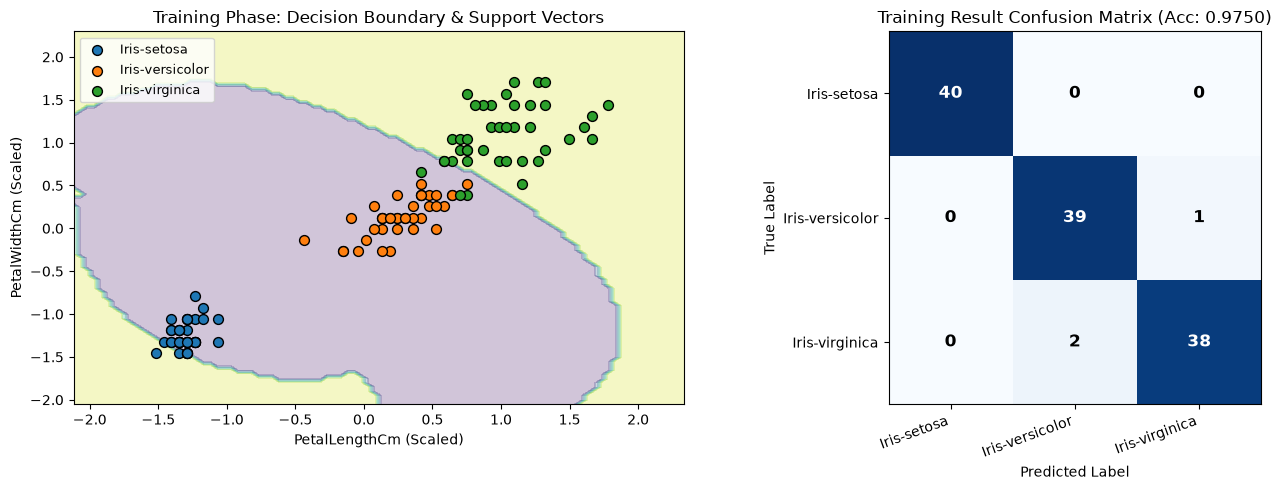

In [28]:
# สร้างโมเดล ManualAdaBoost พร้อมระบุพารามิเตอร์ชัดเจน
# กำหนด C=50.0 เพราะ sample_weight มีผลรวมเป็น 1 (แต่ละจุดหนักประมาณ 1/120)
boosting_model = ManualAdaBoost(
    n_estimators=10,
    learning_rate=0.5,
    kernel="rbf",
    C=50.0,
    gamma="scale",
    random_state=42
)

# ฝึกสอนโมเดล Boosting บนชุดข้อมูล Train เดิม พร้อมแสดงผลในรอบที่ 1 และทุกๆ 2 รอบ
start_time = time.perf_counter()
boosting_model.fit(
    X_train_scaled,
    y_train,
    class_names=label_encoder.classes_,
    plot_every_n_rounds=2
)
boosting_train_time = time.perf_counter() - start_time

# ตรวจสอบผลลัพธ์สุดท้ายของการเทรน และจำนวนรอบที่เทรนจริง
y_pred_train_boosting = boosting_model.predict(X_train_scaled)
boosting_train_accuracy = accuracy_score(y_train, y_pred_train_boosting)

print(f"Training Time: {boosting_train_time:.4f} seconds")
print(f"Rounds Trained: {len(boosting_model.models)} / {boosting_model.n_estimators}")
print(f"Train Accuracy: {boosting_train_accuracy:.4f}")

#### ขั้นตอนการ test (Boosting)

Boosting Test Accuracy: 0.9667

Test Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



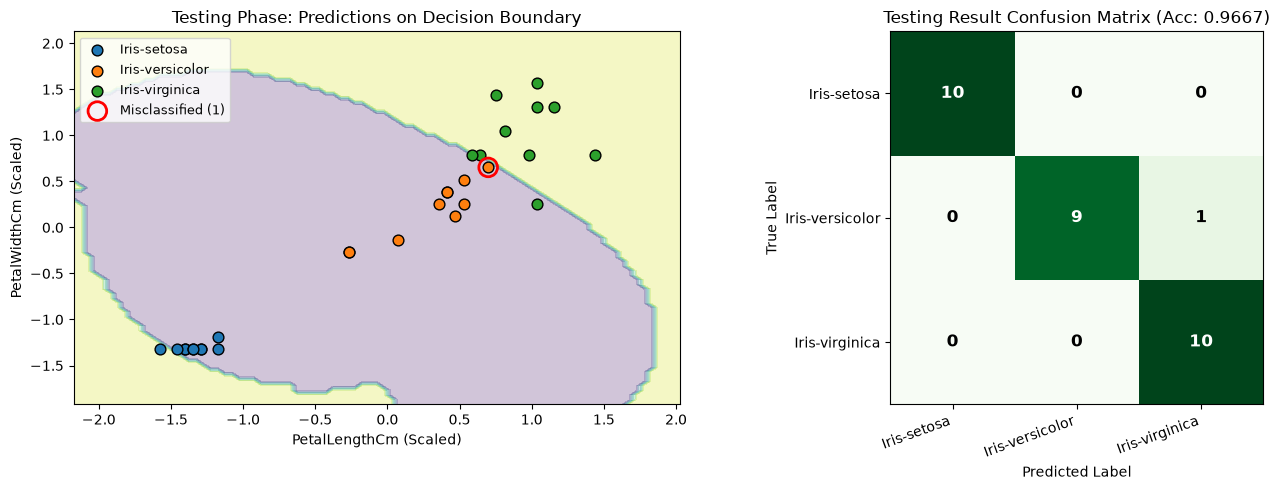

In [29]:
# นำโมเดล Boosting ที่เทรนแล้วมาทำนายผลบนชุดข้อมูล Test เดิม
y_pred_test_boosting = boosting_model.predict(X_test_scaled)
boosting_test_accuracy = accuracy_score(y_test, y_pred_test_boosting)

print(f"Boosting Test Accuracy: {boosting_test_accuracy:.4f}")
print("\nTest Classification Report:")
print(classification_report(y_test, y_pred_test_boosting, target_names=label_encoder.classes_))

# แสดง Visualization ผลลัพธ์สุดท้ายของ Boosting เปรียบเทียบทั้งชุด Train และ Test
plot_boosting_final_summary(
    y_train=y_train,
    y_pred_train=y_pred_train_boosting,
    y_test=y_test,
    y_pred_test=y_pred_test_boosting,
    class_names=label_encoder.classes_
)